# HRRL et interoception : satiation et bruit intéroceptif

**Plan**

1. Imports
2. Configuration (tous les paramètres)
3. Environnement (gridworld, dynamique interne, pénurie, interoception bruitée)
4. Récompenses (A/D HRRL, B maximiseur, C saturante)
5. Agent Double DQN
6. Boucle d'un run (entraînement + vie d'évaluation)
7. Métriques
8. Style des figures
9. **Bac à sable** : un run unique, rapide, pour explorer
10. **Campagne satiation** (conditions A–D × seeds) + figure
11. **Campagne pénurie annoncée** (γ ∈ {0.5, 0.9, 0.99} + contrôle sans indice) + figure


## 1. Imports

In [77]:
import copy
import csv
import glob
import json
import math
import os
import time
from collections import deque
from dataclasses import asdict, dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from joblib import Parallel, delayed

%matplotlib inline

## 2. Configuration

Tous les paramètres expérimentaux sont ici, ce qui permet de reproduire un run à partir de sa config sauvegardée seule. Modifier une valeur par défaut ici change **tous** les runs suivants ; pour ne changer qu'un run, utiliser plutôt `with_overrides` (section 6).

In [78]:
@dataclass
class EnvConfig:
    size: int = 7
    # (row, col, internal variable fed by this resource). Var 0 = energy, var 1 = water.
    # Placed in opposite corners so that satisfying one need costs the other.
    resources: tuple = ((0, 0, 0), (6, 6, 1))
    n_vars: int = 2
    setpoint: float = 10.0
    h_max: float = 20.0           # physiological ceiling (gut capacity)
    init_low: float = 6.0
    init_high: float = 10.0
    bite: float = 1.0             # amount ingested per consume action
    basal_cost: tuple = (0.04, 0.04)   # metabolic loss per step, per variable
    move_cost: tuple = (0.04, 0.02)    # extra loss when attempting to move
    max_steps: int = 1000         # training episode length (truncation, not death)

    # Temporal variant: announced scarcity, during which consuming yields nothing.
    scarcity: bool = False
    scarcity_warning: int = 60    # steps between the cue and the onset
    scarcity_duration: int = 250  # 250 * basal 0.04 = 10 = setpoint: lethal without storage
    scarcity_interval: tuple = (300, 600)  # gap between scarcity episodes
    scarcity_cue: bool = True     # False: the warning is hidden (control for anticipation)


@dataclass
class RewardConfig:
    condition: str = "hrrl"       # "hrrl" | "maximizer" | "saturating"
    drive_n: float = 4.0          # Keramati & Gutkin (2014): D(H) = (sum |h*_i - h_i|^n)^(1/m)
    drive_m: float = 3.0
    sigma: float = 0.0            # interoceptive noise, applied to observation AND reward
    sat_window: int = 50          # saturating control: sliding window (steps)
    sat_cap: tuple = None         # bites rewarded per window per variable; None = matched to metabolic need
    # Same terminal penalty in every condition, so all agents value survival and only
    # the satiation signal differs. ~ drive at death (one variable at 0): (10^4)^(1/3) = 21.5.
    # Set to 0 for pure HRRL, where death only costs the lost future drive reduction.
    death_penalty: float = 20.0


@dataclass
class AgentConfig:
    gamma: float = 0.99
    lr: float = 5e-4
    hidden: int = 128
    buffer_size: int = 100_000
    batch_size: int = 64
    train_every: int = 4
    target_update: int = 1_000
    eps_start: float = 1.0
    eps_end: float = 0.05
    eps_decay_steps: int = 100_000
    learning_starts: int = 2_000
    grad_clip: float = 10.0


@dataclass
class RunConfig:
    seed: int = 0
    train_steps: int = 300_000
    eval_steps: int = 5_000
    eval_eps: float = 0.02
    log_every: int = 1_000
    env: EnvConfig = field(default_factory=EnvConfig)
    reward: RewardConfig = field(default_factory=RewardConfig)
    agent: AgentConfig = field(default_factory=AgentConfig)

    def to_dict(self):
        return asdict(self)

## 3. Environnement

Gridworld avec ressources inépuisables et état interne multidimensionnel.

L'état interne vrai `h` décroît à chaque pas (métabolisme basal), et plus vite quand l'agent bouge. Consommer sur une case ressource ajoute `bite` à la variable nourrie par cette ressource. L'agent meurt quand une variable atteint 0. Aller vers la nourriture coûte de l'eau et inversement : c'est le « cercle de nécessité » auquel l'agent doit s'adapter.

L'environnement ne connaît que l'état **vrai**. Ce que l'agent perçoit est produit par `Interoception`, donc le bruit ne contamine jamais la physiologie.

Actions : 0–3 = haut/bas/gauche/droite, 4 = rester, 5 = consommer.

In [79]:
MOVES = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]])  # up, down, left, right
STAY, CONSUME = 4, 5
N_ACTIONS = 6


class Interoception:
    # Perceived internal state: h_hat = h + N(0, sigma^2), sampled once per time step.
    # The same sample feeds the policy input and the reward, i.e. noise enters both
    # the observation and the drive computation.

    def __init__(self, sigma, rng):
        self.sigma = sigma
        self.rng = rng

    def __call__(self, h):
        if self.sigma == 0:
            return h.copy()
        return h + self.rng.normal(0.0, self.sigma, size=h.shape)


class InteroceptiveGridWorld:
    def __init__(self, cfg, rng):
        self.cfg = cfg
        self.rng = rng
        self.setpoint = np.full(cfg.n_vars, cfg.setpoint)
        self.basal = np.asarray(cfg.basal_cost, dtype=float)
        self.move_cost = np.asarray(cfg.move_cost, dtype=float)
        self.resource_at = {(r, c): v for r, c, v in cfg.resources}
        self.max_steps = cfg.max_steps
        self.obs_dim = cfg.size * cfg.size + cfg.n_vars + (3 if cfg.scarcity else 0)

    # ---- episode control -------------------------------------------------
    def reset(self):
        cfg = self.cfg
        self.pos = self.rng.integers(0, cfg.size, size=2)
        self.h = self.rng.uniform(cfg.init_low, cfg.init_high, size=cfg.n_vars)
        self.t = 0
        if cfg.scarcity:
            self.scarcity_start = cfg.scarcity_warning + self._gap()
            self.scarcity_end = self.scarcity_start + cfg.scarcity_duration

    def _gap(self):
        lo, hi = self.cfg.scarcity_interval
        return int(self.rng.integers(lo, hi + 1))

    # ---- scarcity schedule -----------------------------------------------
    @property
    def in_scarcity(self):
        return self.cfg.scarcity and self.scarcity_start <= self.t < self.scarcity_end

    @property
    def in_warning(self):
        return (self.cfg.scarcity
                and self.scarcity_start - self.cfg.scarcity_warning <= self.t < self.scarcity_start)

    def _scarcity_features(self):
        cfg = self.cfg
        warning = 0.0
        if self.in_warning and cfg.scarcity_cue:
            warning = 1.0 - (self.scarcity_start - self.t) / cfg.scarcity_warning
        remaining = ((self.scarcity_end - self.t) / cfg.scarcity_duration) if self.in_scarcity else 0.0
        return [warning, float(self.in_scarcity), remaining]

    # ---- dynamics ----------------------------------------------------------
    def observation(self, h_perceived):
        cfg = self.cfg
        pos = np.zeros(cfg.size * cfg.size)
        pos[self.pos[0] * cfg.size + self.pos[1]] = 1.0
        parts = [pos, (h_perceived - self.setpoint) / self.setpoint]
        if cfg.scarcity:
            parts.append(self._scarcity_features())
        return np.concatenate(parts).astype(np.float32)

    def step(self, action):
        # Returns (consumed, dead, truncated). `consumed` is the nominal amount
        # ingested per variable this step, before the h_max ceiling.
        cfg = self.cfg
        consumed = np.zeros(cfg.n_vars)
        cost = self.basal.copy()
        if action < 4:
            self.pos = np.clip(self.pos + MOVES[action], 0, cfg.size - 1)
            cost += self.move_cost
        elif action == CONSUME:
            var = self.resource_at.get((int(self.pos[0]), int(self.pos[1])))
            if var is not None and not self.in_scarcity:
                consumed[var] = cfg.bite

        self.h = np.minimum(self.h - cost + consumed, cfg.h_max)
        self.t += 1
        if cfg.scarcity and self.t >= self.scarcity_end:
            self.scarcity_start = self.scarcity_end + self._gap() + cfg.scarcity_warning
            self.scarcity_end = self.scarcity_start + cfg.scarcity_duration

        dead = bool((self.h <= 0).any())
        truncated = (not dead) and self.t >= self.max_steps
        return consumed, dead, truncated

## 4. Récompenses

Toutes les récompenses ont la même signature `reward(h_hat, h_hat_next, consumed)` : l'agent et la boucle d'entraînement sont identiques d'une condition à l'autre, seule la récompense change.

- **A / D — HRRL** : $r_t = D(\hat h_t) - D(\hat h_{t+1})$, avec $D(h) = \left(\sum_i |h^*_i - h_i|^n\right)^{1/m}$, $n=4$, $m=3$. Symétrique : le dépassement est pénalisé comme un déficit.
- **B — maximiseur** : $r$ = quantité ingérée.
- **C — saturante** : +1 par bouchée tant que le quota de la fenêtre glissante n'est pas atteint (quota calé sur le besoin métabolique), aveugle à $h$.

In [80]:
def drive(h, setpoint, n, m):
    # Keramati & Gutkin (2014): D(H) = (sum_i |h*_i - h_i|^n)^(1/m), n > m > 1.
    # Symmetric, so overshooting the setpoint is penalised like a deficit.
    return float((np.abs(setpoint - h) ** n).sum() ** (1.0 / m))


class HomeostaticReward:
    # HRRL: reward = drive reduction, r_t = D(h_hat_t) - D(h_hat_{t+1}).

    def __init__(self, setpoint, n, m):
        self.setpoint, self.n, self.m = setpoint, n, m

    def reset(self):
        pass

    def __call__(self, h_hat, h_hat_next, consumed):
        return (drive(h_hat, self.setpoint, self.n, self.m)
                - drive(h_hat_next, self.setpoint, self.n, self.m))


class MaximizerReward:
    # Reward = quantity consumed. No internal bound at all.

    def reset(self):
        pass

    def __call__(self, h_hat, h_hat_next, consumed):
        return float(consumed.sum())


class SaturatingReward:
    # Hand-coded saturation: a bite of variable i is rewarded (+1) only if fewer than
    # cap_i bites of i occurred in the last `window` steps. Bounded, but blind to the
    # internal state, so it cannot produce state-dependent resumption.

    def __init__(self, caps, window):
        self.caps, self.window = caps, window
        self.reset()

    def reset(self):
        self.t = 0
        self.history = [deque() for _ in self.caps]

    def __call__(self, h_hat, h_hat_next, consumed):
        self.t += 1
        r = 0.0
        for i, amount in enumerate(consumed):
            hist = self.history[i]
            while hist and hist[0] <= self.t - self.window:
                hist.popleft()
            if amount > 0:
                if len(hist) < self.caps[i]:
                    r += 1.0
                hist.append(self.t)
        return r


def matched_caps(env_cfg, window):
    # Bites per window needed to offset metabolism while commuting between resources.
    need = (np.asarray(env_cfg.basal_cost) + np.asarray(env_cfg.move_cost)) * window / env_cfg.bite
    return tuple(int(math.ceil(x)) for x in need)


def make_reward(reward_cfg, env_cfg):
    setpoint = np.full(env_cfg.n_vars, env_cfg.setpoint)
    if reward_cfg.condition == "hrrl":
        return HomeostaticReward(setpoint, reward_cfg.drive_n, reward_cfg.drive_m)
    if reward_cfg.condition == "maximizer":
        return MaximizerReward()
    if reward_cfg.condition == "saturating":
        caps = reward_cfg.sat_cap or matched_caps(env_cfg, reward_cfg.sat_window)
        return SaturatingReward(caps, reward_cfg.sat_window)
    raise ValueError(f"unknown condition {reward_cfg.condition!r}")

Visualisation rapide du drive (une variable à la consigne, l'autre varie) — utile pour voir l'effet de `n` et `m` :

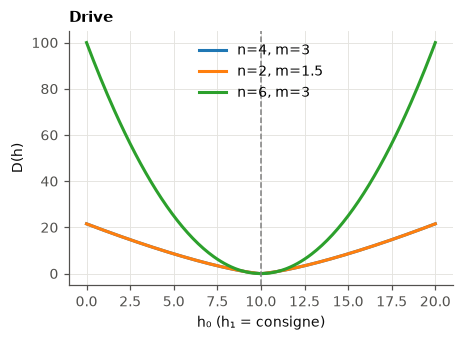

In [81]:
_sp = np.array([10.0, 10.0])
_x = np.linspace(0, 20, 201)
plt.figure(figsize=(4.5, 3))
for n, m in [(4, 3), (2, 1.5), (6, 3)]:
    plt.plot(_x, [drive(np.array([v, 10.0]), _sp, n, m) for v in _x], label=f"n={n}, m={m}")
plt.axvline(10, color="grey", ls="--", lw=1)
plt.xlabel("h₀ (h₁ = consigne)"); plt.ylabel("D(h)"); plt.legend(); plt.title("Drive")
plt.show()

## 5. Agent : Double DQN avec replay buffer uniforme

In [82]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    def __init__(self, obs_dim, size, rng):
        self.obs = np.zeros((size, obs_dim), np.float32)
        self.next_obs = np.zeros((size, obs_dim), np.float32)
        self.act = np.zeros(size, np.int64)
        self.rew = np.zeros(size, np.float32)
        self.done = np.zeros(size, np.float32)
        self.size, self.ptr, self.full = size, 0, False
        self.rng = rng

    def add(self, o, a, r, o2, d):
        i = self.ptr
        self.obs[i], self.act[i], self.rew[i], self.next_obs[i], self.done[i] = o, a, r, o2, d
        self.ptr = (i + 1) % self.size
        self.full = self.full or self.ptr == 0

    def __len__(self):
        return self.size if self.full else self.ptr

    def sample(self, n):
        idx = self.rng.integers(0, len(self), size=n)
        return (torch.from_numpy(self.obs[idx]), torch.from_numpy(self.act[idx]),
                torch.from_numpy(self.rew[idx]), torch.from_numpy(self.next_obs[idx]),
                torch.from_numpy(self.done[idx]))


class DQNAgent:
    def __init__(self, obs_dim, n_actions, cfg, rng):
        self.cfg, self.rng, self.n_actions = cfg, rng, n_actions
        self.q = QNetwork(obs_dim, n_actions, cfg.hidden)
        self.q_target = QNetwork(obs_dim, n_actions, cfg.hidden)
        self.q_target.load_state_dict(self.q.state_dict())
        self.opt = torch.optim.Adam(self.q.parameters(), lr=cfg.lr)
        self.buffer = ReplayBuffer(obs_dim, cfg.buffer_size, rng)

    def epsilon(self, step):
        c = self.cfg
        frac = min(1.0, step / c.eps_decay_steps)
        return c.eps_start + frac * (c.eps_end - c.eps_start)

    def act(self, obs, eps):
        if self.rng.random() < eps:
            return int(self.rng.integers(self.n_actions))
        with torch.no_grad():
            return int(self.q(torch.from_numpy(obs)[None]).argmax(1).item())

    def update(self, step):
        c = self.cfg
        if step < c.learning_starts or step % c.train_every:
            return
        o, a, r, o2, d = self.buffer.sample(c.batch_size)
        with torch.no_grad():
            a2 = self.q(o2).argmax(1, keepdim=True)
            target = r + c.gamma * (1 - d) * self.q_target(o2).gather(1, a2).squeeze(1)
        q = self.q(o).gather(1, a[:, None]).squeeze(1)
        loss = F.smooth_l1_loss(q, target)
        self.opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), c.grad_clip)
        self.opt.step()
        if step % c.target_update == 0:
            self.q_target.load_state_dict(self.q.state_dict())

## 6. Un run : entraînement, puis une vie d'évaluation de `eval_steps` pas

`run_one(cfg, out_path)` renvoie un dict (courbes d'entraînement par bloc de `log_every` pas + trace d'évaluation) et, si `out_path` est donné, le sauvegarde en `.npz` avec la config complète.

`with_overrides(cfg, reward={'sigma': 1}, agent={'gamma': 0.9}, run={'seed': 3})` copie une config en modifiant quelques champs.

In [83]:
def run_one(cfg, out_path=None, verbose=False):
    torch.set_num_threads(1)
    torch.manual_seed(cfg.seed)
    rng = np.random.default_rng(cfg.seed)

    env = InteroceptiveGridWorld(cfg.env, rng)
    intero = Interoception(cfg.reward.sigma, rng)
    reward_fn = make_reward(cfg.reward, cfg.env)
    agent = DQNAgent(env.obs_dim, N_ACTIONS, cfg.agent, rng)
    setpoint = env.setpoint

    def new_life():
        env.reset()
        reward_fn.reset()
        h_hat = intero(env.h)
        return h_hat, env.observation(h_hat)

    # ---- training ---------------------------------------------------------
    n_blocks = cfg.train_steps // cfg.log_every
    train_log = {k: np.zeros((n_blocks,) + s) for k, s in [
        ("intake", (cfg.env.n_vars,)), ("deaths", ()), ("abs_dev", ()), ("reward", ())]}
    h_hat, obs = new_life()
    t0 = time.time()
    for step in range(cfg.train_steps):
        a = agent.act(obs, agent.epsilon(step))
        consumed, dead, truncated = env.step(a)
        h_hat_next = intero(env.h)
        r = reward_fn(h_hat, h_hat_next, consumed) - dead * cfg.reward.death_penalty
        obs_next = env.observation(h_hat_next)
        agent.buffer.add(obs, a, r, obs_next, float(dead))
        agent.update(step)

        b = step // cfg.log_every
        if b < n_blocks:
            train_log["intake"][b] += consumed
            train_log["deaths"][b] += dead
            train_log["abs_dev"][b] += np.abs(env.h - setpoint).mean()
            train_log["reward"][b] += r

        if dead or truncated:
            h_hat, obs = new_life()
        else:
            h_hat, obs = h_hat_next, obs_next
        if verbose and (step + 1) % max(1, cfg.train_steps // 10) == 0:
            print(f"  train {step + 1}/{cfg.train_steps}  ({time.time() - t0:.0f}s)", flush=True)
    for k in ("intake", "abs_dev", "reward"):
        train_log[k] /= cfg.log_every

    # ---- evaluation: one continuous life, reset only on death -------------
    env.max_steps = cfg.eval_steps + 1
    T = cfg.eval_steps
    trace = {
        "h": np.zeros((T, cfg.env.n_vars)), "h_hat": np.zeros((T, cfg.env.n_vars)),
        "consumed": np.zeros((T, cfg.env.n_vars)), "pos": np.zeros((T, 2), np.int64),
        "dead": np.zeros(T, bool), "warning": np.zeros(T, bool), "scarcity": np.zeros(T, bool),
    }
    h_hat, obs = new_life()
    for t in range(T):
        trace["warning"][t], trace["scarcity"][t] = env.in_warning, env.in_scarcity
        a = agent.act(obs, cfg.eval_eps)
        consumed, dead, _ = env.step(a)
        h_hat_next = intero(env.h)
        trace["h"][t], trace["h_hat"][t], trace["consumed"][t] = env.h, h_hat_next, consumed
        trace["pos"][t], trace["dead"][t] = env.pos, dead
        if dead:
            h_hat, obs = new_life()
        else:
            h_hat, obs = h_hat_next, env.observation(h_hat_next)

    result = {**{f"train_{k}": v for k, v in train_log.items()}, **trace}
    if out_path:
        os.makedirs(os.path.dirname(out_path), exist_ok=True)
        tmp = out_path + ".tmp.npz"
        np.savez_compressed(tmp, config=json.dumps(cfg.to_dict()), **result)
        os.replace(tmp, out_path)
    return result


def with_overrides(cfg, **sections):
    # Copy a RunConfig, overriding fields per section: with_overrides(cfg, reward={'sigma': 1}).
    cfg = copy.deepcopy(cfg)
    for section, values in sections.items():
        target = cfg if section == "run" else getattr(cfg, section)
        for k, v in values.items():
            setattr(target, k, v)
    return cfg

## 7. Métriques

Satiation et stockage, calculés sur les traces d'évaluation (état interne **vrai**).

In [84]:
def intake_rate(consumed, window=100):
    # Bites per step, summed over variables, in non-overlapping windows.
    total = consumed.sum(1)
    n = len(total) // window
    return total[: n * window].reshape(n, window).mean(1)


def time_near_setpoint(h, setpoint, tol=2.0):
    # Fraction of time each variable is within tol of its setpoint, averaged over
    # variables. (Requiring all variables at once is too strict: commuting between
    # resources makes them oscillate out of phase.)
    return float((np.abs(h - setpoint) < tol).mean())


def overshoot(h, setpoint):
    # Mean excess above setpoint, averaged over steps and variables.
    return float(np.clip(h - setpoint, 0, None).mean())


def resumption_latency(h, consumed, setpoint, theta=1.0):
    # After h_i drops below setpoint - theta (downward crossing), steps until the next
    # bite of variable i. Returns (median latency, fraction of crossings followed by a
    # bite before the end of the trace). NaN latency if there was no crossing.
    latencies, n_events, n_resumed = [], 0, 0
    thr = setpoint - theta
    for i in range(h.shape[1]):
        below = h[:, i] < thr
        crossings = np.flatnonzero(below[1:] & ~below[:-1]) + 1
        bites = np.flatnonzero(consumed[:, i] > 0)
        for c in crossings:
            n_events += 1
            nxt = bites[bites >= c]
            if len(nxt):
                n_resumed += 1
                latencies.append(nxt[0] - c)
    lat = float(np.median(latencies)) if latencies else np.nan
    return lat, (n_resumed / n_events if n_events else np.nan)


def satiation_summary(trace, setpoint, tol=2.0, theta=1.0):
    h, consumed = trace["h"], trace["consumed"]
    lat, resumed = resumption_latency(h, consumed, setpoint, theta)
    return {
        "near_setpoint": time_near_setpoint(h, setpoint, tol),
        "abs_dev": float(np.abs(h - setpoint).mean()),
        "overshoot": overshoot(h, setpoint),
        "intake": float(consumed.sum(1).mean()),
        "resume_latency": lat,
        "resume_frac": resumed,
        "deaths": int(trace["dead"].sum()),
    }


def storage_summary(trace, setpoint, lookback=5):
    # Storage = mean excess of h above setpoint just before scarcity onset, versus
    # the same quantity outside warning/scarcity periods (baseline).
    h, sc, warn = trace["h"], trace["scarcity"], trace["warning"]
    onsets = np.flatnonzero(sc[1:] & ~sc[:-1]) + 1
    pre = [h[o - lookback:o].mean() for o in onsets if o >= lookback]
    calm = ~(sc | warn)
    # a scarcity is survived if no death occurs between its onset and its end
    survived = []
    for o in onsets:
        end = o + np.argmax(~sc[o:]) if (~sc[o:]).any() else len(sc)
        survived.append(not trace["dead"][o:end].any())
    return {
        "pre_scarcity_level": float(np.mean(pre)) - setpoint if pre else np.nan,
        "baseline_level": float(h[calm].mean()) - setpoint if calm.any() else np.nan,
        "survival": float(np.mean(survived)) if survived else np.nan,
        "deaths": int(trace["dead"].sum()),
    }

## 8. Style des figures et utilitaires

In [85]:
# Categorical slots in fixed order (validated colour-blind-safe order).
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COND_COLORS = {"hrrl": BLUE, "maximizer": ORANGE, "saturating": AQUA}
COND_LABELS = {"hrrl": "A  HRRL", "maximizer": "B  maximizer", "saturating": "C  saturating"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "lines.linewidth": 2,
    "legend.frameon": False,
})


def read_csv(path):
    with open(path) as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        for k, v in r.items():
            try:
                r[k] = float(v)
            except ValueError:
                pass
    return rows


def mean_sem(values):
    v = np.asarray([x for x in values if not np.isnan(x)], float)
    if len(v) == 0:
        return np.nan, np.nan
    return v.mean(), (v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0)


def run_campaign(jobs, job_fn, workers):
    # Runs job_fn over jobs, in parallel if workers > 1. joblib (loky backend) starts
    # fresh processes and ships the functions defined in this notebook to them, so
    # edits made in the cells above are picked up by the workers.
    print(f"{len(jobs)} runs on {workers} worker(s)")
    if workers <= 1:
        results = map(job_fn, jobs)
    else:
        results = Parallel(n_jobs=workers, return_as="generator_unordered")(
            delayed(job_fn)(j) for j in jobs)
    for i, (name, seed, dt) in enumerate(results, 1):
        print(f"[{i}/{len(jobs)}] {name} seed {seed} ({dt:.0f}s)", flush=True)

## 9. Bac à sable : un run unique

Pour tester une idée rapidement. Avec `train_steps = 30_000`, compter ~30 s à 1 min. Modifier librement les overrides.

In [86]:
demo_cfg = with_overrides(
    RunConfig(),
    run={"seed": 5, "train_steps": 30_000, "eval_steps": 2_000},
    reward={"condition": "hrrl", "sigma": 0.0},   # "hrrl" | "maximizer" | "saturating"
    agent={"eps_decay_steps": 15_000},
)
t = time.time()
demo = run_one(demo_cfg, verbose=True)
print(f"done in {time.time() - t:.0f}s")
satiation_summary(demo, demo_cfg.env.setpoint)

  train 3000/30000  (0s)
  train 6000/30000  (1s)
  train 9000/30000  (1s)
  train 12000/30000  (2s)
  train 15000/30000  (3s)
  train 18000/30000  (3s)
  train 21000/30000  (4s)
  train 24000/30000  (4s)
  train 27000/30000  (5s)
  train 30000/30000  (6s)
done in 6s


{'near_setpoint': 0.0935,
 'abs_dev': 5.32474884424714,
 'overshoot': 0.047788983984693424,
 'intake': 0.021,
 'resume_latency': 847.5,
 'resume_frac': 0.5,
 'deaths': 10}

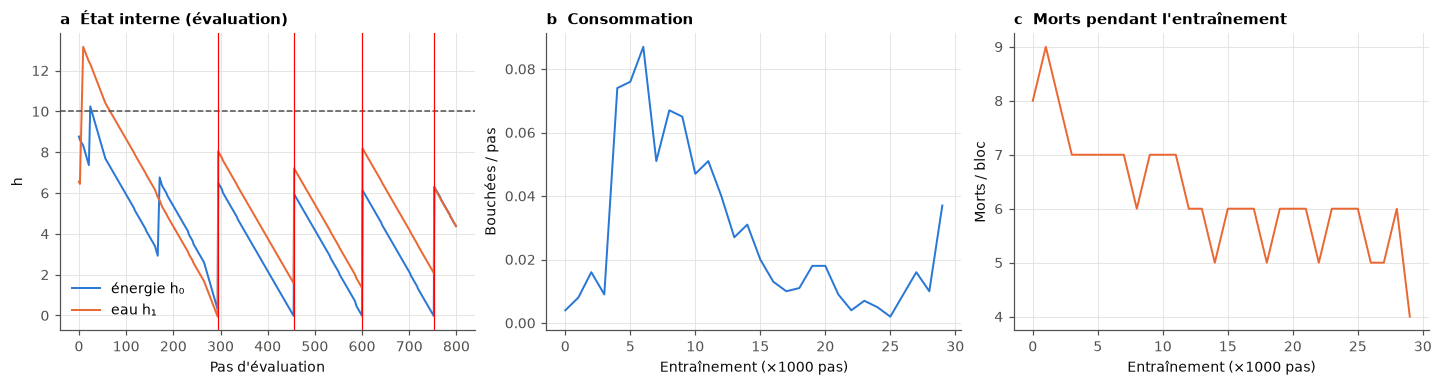

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), constrained_layout=True)
ax = axes[0]
ax.plot(demo["h"][:800, 0], label="énergie h₀", color=BLUE, lw=1.3)
ax.plot(demo["h"][:800, 1], label="eau h₁", color=ORANGE, lw=1.3)
ax.axhline(demo_cfg.env.setpoint, color=INK_2, ls="--", lw=1)
for t_dead in np.flatnonzero(demo["dead"][:800]):
    ax.axvline(t_dead, color="red", lw=0.8)
ax.set(xlabel="Pas d'évaluation", ylabel="h", title="a  État interne (évaluation)")
ax.legend()

ax = axes[1]
ax.plot(demo["train_intake"].sum(1), color=BLUE, lw=1.3)
ax.set(xlabel="Entraînement (×1000 pas)", ylabel="Bouchées / pas", title="b  Consommation")

ax = axes[2]
ax.plot(demo["train_deaths"], color=ORANGE, lw=1.3)
ax.set(xlabel="Entraînement (×1000 pas)", ylabel="Morts / bloc", title="c  Morts pendant l'entraînement")
plt.show()

## 10. Campagne satiation (point 4)

| Nom | Condition |
|---|---|
| `A_hrrl` | HRRL, interoception exacte (σ = 0) |
| `B_maximizer` | même agent, r = quantité ingérée |
| `C_saturating` | même agent, récompense saturante codée à la main |
| `D_hrrl_sigma{σ}` | HRRL avec bruit intéroceptif σ (observation + récompense) |

Quick = False 



In [88]:

# 1. Mémoire intéroceptive
@dataclass
class MemoryConfig:
    # "none"   : l'agent voit l'échantillon bruité courant (comportement actuel)
    # "stack"  : les k derniers échantillons bruités (mémoire apprise par le réseau)
    # "ema"    : échantillon courant + moyenne glissante exponentielle
    # "kalman" : estimation d'un filtre de Kalman scalaire qui CONNAÎT la dynamique
    #            (référence « inférence idéale », pas une règle apprise)
    mode: str = "none"
    k: int = 8
    alpha: float = 0.2      # ema : poids du nouvel échantillon
    q: float = 0.01         # kalman : variance de processus par pas (erreur de modèle)


@dataclass
class RunConfig:
    seed: int = 0
    train_steps: int = 300_000
    eval_steps: int = 5_000
    eval_eps: float = 0.02
    log_every: int = 1_000
    env: EnvConfig = field(default_factory=EnvConfig)
    reward: RewardConfig = field(default_factory=RewardConfig)
    agent: AgentConfig = field(default_factory=AgentConfig)
    memory: MemoryConfig = field(default_factory=MemoryConfig)

    def to_dict(self):
        return asdict(self)


class InteroMemory:
    """Transforme la suite d'échantillons bruités h_hat en entrée intéroceptive de l'agent.

    Appelée exactement une fois par échantillon : reset() au premier de la vie,
    update() ensuite. `delta` = variation NOMINALE de h due à l'action
    (-coûts + bouchée) : l'agent connaît son action et ce qu'il a avalé, ce n'est
    donc pas une fuite d'information sur h.
    """

    def __init__(self, cfg, n_vars, setpoint, sigma, h_max):
        self.cfg, self.n, self.sp, self.sigma, self.h_max = cfg, n_vars, setpoint, sigma, h_max
        sizes = {"none": 1, "stack": cfg.k, "ema": 2, "kalman": 1}
        if cfg.mode not in sizes:
            raise ValueError(f"unknown memory mode {cfg.mode!r}")
        self.dim = sizes[cfg.mode] * n_vars

    def _norm(self, x):
        return (x - self.sp) / self.sp

    def reset(self, z):
        self.z = z.copy()
        self.stack = [z.copy() for _ in range(self.cfg.k)]   # 1er échantillon répété
        self.ema = z.copy()
        self.x = z.copy()                                    # estimation kalman
        self.P = np.full(self.n, self.sigma ** 2)

    def update(self, z, delta):
        self.z = z.copy()
        self.stack = self.stack[1:] + [z.copy()]
        a = self.cfg.alpha
        self.ema = (1 - a) * self.ema + a * z
        # Kalman scalaire par variable : prédiction par la dynamique connue, puis correction
        pred = np.minimum(self.x + delta, self.h_max)
        P = self.P + self.cfg.q
        R = self.sigma ** 2
        K = P / (P + R) if (P + R).all() else np.ones(self.n)
        self.x = pred + K * (z - pred)
        self.P = (1 - K) * P

    def features(self):
        mode = self.cfg.mode
        if mode == "none":
            return self._norm(self.z)
        if mode == "stack":
            return np.concatenate([self._norm(s) for s in self.stack])
        if mode == "ema":
            return np.concatenate([self._norm(self.z), self._norm(self.ema)])
        return self._norm(self.x)  # kalman


class MemGridWorld(InteroceptiveGridWorld):
    # Même environnement ; l'observation passe par InteroMemory.

    def __init__(self, cfg, rng, memory):
        super().__init__(cfg, rng)
        self.memory = memory
        self.obs_dim = cfg.size * cfg.size + memory.dim + (3 if cfg.scarcity else 0)
        self.last_delta = np.zeros(cfg.n_vars)
        self._fresh = True

    def reset(self):
        super().reset()
        self.last_delta = np.zeros(self.cfg.n_vars)
        self._fresh = True

    def step(self, action):
        consumed, dead, truncated = super().step(action)
        cost = self.basal + (self.move_cost if action < 4 else 0.0)
        self.last_delta = consumed - cost   # nominal (avant plafond h_max)
        return consumed, dead, truncated

    def observation(self, h_perceived):
        if self._fresh:
            self.memory.reset(h_perceived)
            self._fresh = False
        else:
            self.memory.update(h_perceived, self.last_delta)
        cfg = self.cfg
        pos = np.zeros(cfg.size * cfg.size)
        pos[self.pos[0] * cfg.size + self.pos[1]] = 1.0
        parts = [pos, self.memory.features()]
        if cfg.scarcity:
            parts.append(self._scarcity_features())
        return np.concatenate(parts).astype(np.float32)


# ---------------------------------------------------------------------
# 2. run_one avec flux aléatoires séparés et appariés
#    - flux « agent » (epsilon-greedy, replay), flux « bruit » : indépendants
#    - flux « environnement » : un flux PAR VIE, dérivé de (seed, phase, n° de vie).
#      La vie k a donc le même état initial, la même position et le même calendrier
#      de pénurie dans toutes les conditions qui partagent la seed.
# ---------------------------------------------------------------------
_PHASE = {"train": 1, "eval": 2}


def run_one(cfg, out_path=None, verbose=False):
    torch.set_num_threads(1)
    torch.manual_seed(cfg.seed)
    ss_agent, ss_noise = np.random.SeedSequence([cfg.seed, 0]).spawn(2)
    rng_agent, rng_noise = np.random.default_rng(ss_agent), np.random.default_rng(ss_noise)

    setpoint = np.full(cfg.env.n_vars, cfg.env.setpoint)
    memory = InteroMemory(cfg.memory, cfg.env.n_vars, setpoint, cfg.reward.sigma, cfg.env.h_max)
    env = MemGridWorld(cfg.env, np.random.default_rng(0), memory)  # rng remplacé à chaque vie
    intero = Interoception(cfg.reward.sigma, rng_noise)
    reward_fn = make_reward(cfg.reward, cfg.env)
    agent = DQNAgent(env.obs_dim, N_ACTIONS, cfg.agent, rng_agent)
    lives = {"train": 0, "eval": 0}
    eval_init = []

    def new_life(phase="train"):
        env.rng = np.random.default_rng(np.random.SeedSequence([cfg.seed, _PHASE[phase], lives[phase]]))
        lives[phase] += 1
        env.reset()
        if phase == "eval":
            eval_init.append(np.concatenate([env.pos, env.h]))
        reward_fn.reset()
        h_hat = intero(env.h)
        return h_hat, env.observation(h_hat)

    # ---- entraînement ------------------------------------------------------
    n_blocks = cfg.train_steps // cfg.log_every
    train_log = {k: np.zeros((n_blocks,) + s) for k, s in [
        ("intake", (cfg.env.n_vars,)), ("deaths", ()), ("abs_dev", ()), ("reward", ())]}
    h_hat, obs = new_life("train")
    t0 = time.time()
    for step in range(cfg.train_steps):
        a = agent.act(obs, agent.epsilon(step))
        consumed, dead, truncated = env.step(a)
        h_hat_next = intero(env.h)
        r = reward_fn(h_hat, h_hat_next, consumed) - dead * cfg.reward.death_penalty
        obs_next = env.observation(h_hat_next)
        agent.buffer.add(obs, a, r, obs_next, float(dead))
        agent.update(step)

        b = step // cfg.log_every
        if b < n_blocks:
            train_log["intake"][b] += consumed
            train_log["deaths"][b] += dead
            train_log["abs_dev"][b] += np.abs(env.h - setpoint).mean()
            train_log["reward"][b] += r

        if dead or truncated:
            h_hat, obs = new_life("train")
        else:
            h_hat, obs = h_hat_next, obs_next
        if verbose and (step + 1) % max(1, cfg.train_steps // 10) == 0:
            print(f"  train {step + 1}/{cfg.train_steps}  ({time.time() - t0:.0f}s)", flush=True)
    for k in ("intake", "abs_dev", "reward"):
        train_log[k] /= cfg.log_every

    # ---- évaluation : une vie continue, réinitialisée seulement à la mort ----
    env.max_steps = cfg.eval_steps + 1
    T = cfg.eval_steps
    trace = {
        "h": np.zeros((T, cfg.env.n_vars)), "h_hat": np.zeros((T, cfg.env.n_vars)),
        "consumed": np.zeros((T, cfg.env.n_vars)), "pos": np.zeros((T, 2), np.int64),
        "dead": np.zeros(T, bool), "warning": np.zeros(T, bool), "scarcity": np.zeros(T, bool),
    }
    h_hat, obs = new_life("eval")
    for t in range(T):
        trace["warning"][t], trace["scarcity"][t] = env.in_warning, env.in_scarcity
        a = agent.act(obs, cfg.eval_eps)
        consumed, dead, _ = env.step(a)
        h_hat_next = intero(env.h)
        trace["h"][t], trace["h_hat"][t], trace["consumed"][t] = env.h, h_hat_next, consumed
        trace["pos"][t], trace["dead"][t] = env.pos, dead
        if dead:
            h_hat, obs = new_life("eval")
        else:
            h_hat, obs = h_hat_next, env.observation(h_hat_next)

    result = {**{f"train_{k}": v for k, v in train_log.items()}, **trace,
              "eval_life_init": np.array(eval_init)}   # [row, col, h0, h1] de chaque vie d'éval
    if out_path:
        os.makedirs(os.path.dirname(out_path), exist_ok=True)
        tmp = out_path + ".tmp.npz"
        np.savez_compressed(tmp, config=json.dumps(cfg.to_dict()), **result)
        os.replace(tmp, out_path)
    return result


# ---------------------------------------------------------------------
# 3. Conditions de la campagne : ajout des conditions E (mémoire)
#    Le nom du fichier contient un hash de la config -> plus de cache périmé.
# ---------------------------------------------------------------------
import hashlib

MEM_MODES = ("stack", "ema", "kalman")
MEM_SIGMAS = (1.0, 2.0)   # σ auxquels on teste la mémoire (réduit pour économiser du calcul)


def satiation_conditions(sigmas):
    conds = {
        "A_hrrl": {"condition": "hrrl", "sigma": 0.0, "memory": "none"},
        "B_maximizer": {"condition": "maximizer", "sigma": 0.0, "memory": "none"},
        "C_saturating": {"condition": "saturating", "sigma": 0.0, "memory": "none"},
    }
    for s in sigmas:
        conds[f"D_hrrl_sigma{s:g}"] = {"condition": "hrrl", "sigma": s, "memory": "none"}
    for mode in MEM_MODES:
        for s in MEM_SIGMAS:
            conds[f"E_{mode}_sigma{s:g}"] = {"condition": "hrrl", "sigma": s, "memory": mode}
    return conds


def _cfg_hash(cfg):
    d = cfg.to_dict()
    d.pop("seed", None)
    return hashlib.md5(json.dumps(d, sort_keys=True).encode()).hexdigest()[:8]


def satiation_cfg(reward, seed, train_steps):
    return with_overrides(
        RunConfig(),
        run={"seed": seed, "train_steps": train_steps},
        reward={"condition": reward["condition"], "sigma": reward["sigma"]},
        memory={"mode": reward.get("memory", "none")},
    )


def satiation_path(name, seed, out, reward, train_steps):
    h = _cfg_hash(satiation_cfg(reward, seed, train_steps))
    return os.path.join(out, f"{name}_seed{seed}_{h}.npz")


def satiation_job(args):
    name, reward, seed, train_steps, out = args
    path = satiation_path(name, seed, out, reward, train_steps)
    if os.path.exists(path):
        return name, seed, 0.0
    t = time.time()
    run_one(satiation_cfg(reward, seed, train_steps), path)
    return name, seed, time.time() - t


def summarize_satiation(out, conds, seeds, setpoint, train_steps=None):
    train_steps = train_steps or SAT_TRAIN_STEPS
    rows = []
    for name, reward in conds.items():
        for seed in range(seeds):
            path = satiation_path(name, seed, out, reward, train_steps)
            if not os.path.exists(path):
                continue
            with np.load(path) as d:
                s = satiation_summary(d, setpoint)
            # "reward" = "hrrl" seulement pour A/D : le panel_metric d'origine ignore donc E.
            label = reward["condition"] if reward["memory"] == "none" else f"hrrl_{reward['memory']}"
            rows.append({"condition": name, "reward": label, "memory": reward["memory"],
                         "sigma": reward["sigma"], "seed": seed, **s})
    with open(os.path.join(out, "summary.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)
    print(f"\n{'condition':<22}{'near':>7}{'|dev|':>7}{'oversh':>8}{'intake':>8}{'latency':>9}{'deaths':>8}")
    for name in conds:
        r = [x for x in rows if x["condition"] == name]
        if not r:
            continue
        m = lambda k: np.nanmean([x[k] for x in r])
        print(f"{name:<22}{m('near_setpoint'):7.2f}{m('abs_dev'):7.2f}{m('overshoot'):8.2f}{m('intake'):8.3f}"
              f"{m('resume_latency'):9.1f}{m('deaths'):8.1f}")
    return rows


# ---------------------------------------------------------------------
# 4. Figure : la mémoire compense-t-elle le bruit ?
#    Lecture : si "none" se dégrade avec σ et que stack/ema/kalman restent proches
#    de σ = 0, l'inférence intéroceptive compte. Si rien ne change, l'effet du bruit
#    n'est pas un problème d'estimation.
# ---------------------------------------------------------------------
def plot_memory(out):
    rows = read_csv(os.path.join(out, "summary.csv"))
    metrics = [("near_setpoint", "Time near setpoint"), ("resume_latency", "Resumption latency"),
               ("deaths", "Deaths per 5000-step life")]
    colors = {"none": BLUE, "stack": ORANGE, "ema": AQUA, "kalman": YELLOW}
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
    for ax, (key, title) in zip(axes, metrics):
        for mode in ("none", *MEM_MODES):
            sub = [r for r in rows if r["memory"] == mode and (mode != "none" or r["reward"] == "hrrl")]
            sigmas = sorted({r["sigma"] for r in sub})
            if mode != "none":
                sigmas = [s for s in sigmas if s > 0]
            stats = [mean_sem([r[key] for r in sub if r["sigma"] == s]) for s in sigmas]
            if stats:
                m, e = np.array(stats).T
                ax.errorbar(sigmas, m, yerr=1.96 * e, color=colors[mode], marker="o", ms=4,
                            capsize=3, label=mode)
        ax.set(xlabel="Interoceptive noise σ", title=title)
    axes[0].legend()
    path = os.path.join(out, "fig_memory.png")
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)
    plt.show()

In [89]:
QUICK = False

SAT_SEEDS = 2 if QUICK else 30
SAT_TRAIN_STEPS = 30_000 if QUICK else RunConfig.train_steps
SAT_OUT = "results/nb_smoke_satiation" if QUICK else "results/satiation"
SIGMAS = (0.5, 1.0, 2.0, 4.0)
SAT_ONLY = None            # e.g. ["A_hrrl", "D_hrrl_sigma1"] to run a subset
WORKERS = max(1, os.cpu_count() - 2)

In [90]:
def satiation_conditions(sigmas):
    conds = {
        "A_hrrl": {"condition": "hrrl", "sigma": 0.0},
        "B_maximizer": {"condition": "maximizer", "sigma": 0.0},
        "C_saturating": {"condition": "saturating", "sigma": 0.0},
    }
    for s in sigmas:
        conds[f"D_hrrl_sigma{s:g}"] = {"condition": "hrrl", "sigma": s}
    return conds


def satiation_job(args):
    name, reward, seed, train_steps, out = args
    path = os.path.join(out, f"{name}_seed{seed}.npz")
    if os.path.exists(path):
        return name, seed, 0.0
    cfg = with_overrides(RunConfig(), run={"seed": seed, "train_steps": train_steps}, reward=reward)
    t = time.time()
    run_one(cfg, path)
    return name, seed, time.time() - t


def summarize_satiation(out, conds, seeds, setpoint):
    rows = []
    for name, reward in conds.items():
        for seed in range(seeds):
            path = os.path.join(out, f"{name}_seed{seed}.npz")
            if not os.path.exists(path):
                continue
            with np.load(path) as d:
                s = satiation_summary(d, setpoint)
            rows.append({"condition": name, "reward": reward["condition"],
                         "sigma": reward["sigma"], "seed": seed, **s})
    with open(os.path.join(out, "summary.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)
    print(f"\n{'condition':<22}{'near':>7}{'|dev|':>7}{'oversh':>8}{'intake':>8}{'latency':>9}{'deaths':>8}")
    for name in conds:
        r = [x for x in rows if x["condition"] == name]
        m = lambda k: np.nanmean([x[k] for x in r])
        print(f"{name:<22}{m('near_setpoint'):7.2f}{m('abs_dev'):7.2f}{m('overshoot'):8.2f}{m('intake'):8.3f}"
              f"{m('resume_latency'):9.1f}{m('deaths'):8.1f}")
    return rows

In [91]:
sat_conds = satiation_conditions(SIGMAS)
if SAT_ONLY:
    sat_conds = {k: v for k, v in sat_conds.items() if k in SAT_ONLY}
os.makedirs(SAT_OUT, exist_ok=True)
sat_jobs = [(n, r, s, SAT_TRAIN_STEPS, SAT_OUT) for s in range(SAT_SEEDS) for n, r in sat_conds.items()]
run_campaign(sat_jobs, satiation_job, WORKERS)

210 runs on 8 worker(s)
[1/210] B_maximizer seed 0 (164s)
[2/210] C_saturating seed 0 (171s)
[3/210] A_hrrl seed 1 (172s)
[4/210] D_hrrl_sigma4 seed 0 (174s)
[5/210] D_hrrl_sigma1 seed 0 (175s)
[6/210] A_hrrl seed 0 (175s)
[7/210] D_hrrl_sigma0.5 seed 0 (177s)
[8/210] D_hrrl_sigma2 seed 0 (177s)
[9/210] B_maximizer seed 1 (171s)
[10/210] C_saturating seed 1 (174s)
[11/210] B_maximizer seed 2 (168s)
[12/210] D_hrrl_sigma1 seed 1 (175s)
[13/210] D_hrrl_sigma0.5 seed 1 (177s)
[14/210] A_hrrl seed 2 (173s)
[15/210] D_hrrl_sigma2 seed 1 (176s)
[16/210] D_hrrl_sigma4 seed 1 (179s)
[17/210] C_saturating seed 2 (201s)
[18/210] B_maximizer seed 3 (196s)
[19/210] D_hrrl_sigma0.5 seed 2 (204s)
[20/210] D_hrrl_sigma1 seed 2 (206s)
[21/210] A_hrrl seed 3 (202s)
[22/210] D_hrrl_sigma2 seed 2 (204s)
[23/210] D_hrrl_sigma4 seed 2 (207s)
[24/210] C_saturating seed 3 (204s)
[25/210] D_hrrl_sigma0.5 seed 3 (180s)
[26/210] B_maximizer seed 4 (170s)
[27/210] D_hrrl_sigma1 seed 3 (179s)
[28/210] D_hrrl_sigm

In [92]:
sat_rows = summarize_satiation(SAT_OUT, sat_conds, SAT_SEEDS, RunConfig().env.setpoint)


condition                near  |dev|  oversh  intake  latency  deaths
A_hrrl                   0.53   2.46    0.21   0.098     92.2     3.7
B_maximizer              0.04   7.72    4.70   0.956    151.6    25.2
C_saturating             0.08   5.60    0.03   0.063    199.3    21.6
D_hrrl_sigma0.5          0.30   3.76    0.23   0.075    134.2    17.5
D_hrrl_sigma1            0.11   5.31    0.05   0.022    391.8    35.6
D_hrrl_sigma2            0.08   5.47    0.08   0.011    671.2    37.8
D_hrrl_sigma4            0.07   5.53    0.03   0.003    611.6    39.5


### Figure satiation : comment le bruit intéroceptif dégrade la satiation

Peut être relancée seule à partir des résultats sauvegardés (y compris ceux produits par `run_satiation.py`) : il suffit d'exécuter les sections 1–8 puis de régler `SAT_OUT`.

saved results/satiation/fig_satiation.png


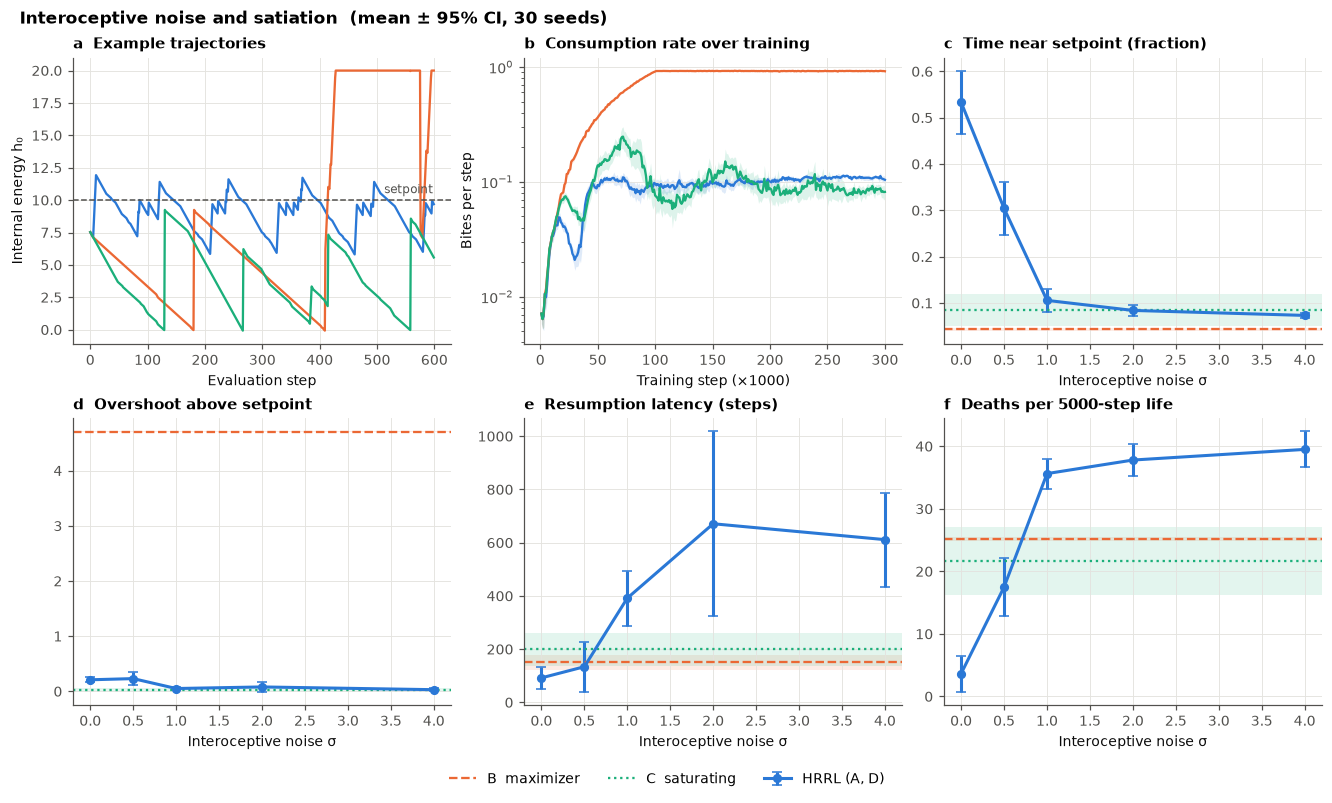

In [93]:
SAT_METRICS = [
    ("near_setpoint", "Time near setpoint (fraction)"),
    ("overshoot", "Overshoot above setpoint"),
    ("resume_latency", "Resumption latency (steps)"),
    ("deaths", "Deaths per 5000-step life"),
]


def panel_metric(ax, rows, key, label):
    hrrl = sorted({r["sigma"] for r in rows if r["reward"] == "hrrl"})
    stats = [mean_sem([r[key] for r in rows if r["reward"] == "hrrl" and r["sigma"] == s]) for s in hrrl]
    m, e = np.array(stats).T
    ax.errorbar(hrrl, m, yerr=1.96 * e, color=BLUE, marker="o", ms=5, capsize=3, label="HRRL (A, D)")
    # B and C have no interoceptive noise: drawn as reference levels across the sigma axis.
    for cond, ls in (("maximizer", "--"), ("saturating", ":")):
        vals = [r[key] for r in rows if r["reward"] == cond]
        if vals:
            mu, se = mean_sem(vals)
            ax.axhline(mu, color=COND_COLORS[cond], ls=ls, lw=1.5, label=COND_LABELS[cond])
            ax.axhspan(mu - 1.96 * se, mu + 1.96 * se, color=COND_COLORS[cond], alpha=0.12, lw=0)
    ax.set_xlabel("Interoceptive noise σ")
    ax.set_title(label)


def plot_satiation(out, example_seed=0, setpoint=10.0):
    rows = read_csv(os.path.join(out, "summary.csv"))
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), constrained_layout=True)

    # (a) example trajectories: energy variable during the evaluation life
    ax = axes[0, 0]
    for cond, name in (("hrrl", "A_hrrl"), ("maximizer", "B_maximizer"), ("saturating", "C_saturating")):
        path = os.path.join(out, f"{name}_seed{example_seed}.npz")
        if os.path.exists(path):
            with np.load(path) as d:
                ax.plot(d["h"][:600, 0], color=COND_COLORS[cond], lw=1.5, label=COND_LABELS[cond])
    ax.axhline(setpoint, color=INK_2, ls="--", lw=1)
    ax.text(598, setpoint + 0.3, "setpoint", ha="right", va="bottom", color=INK_2, fontsize=8)
    ax.set(xlabel="Evaluation step", ylabel="Internal energy h₀", title="a  Example trajectories")

    # (b) intake over training, mean across seeds
    ax = axes[0, 1]
    for cond, name in (("hrrl", "A_hrrl"), ("maximizer", "B_maximizer"), ("saturating", "C_saturating")):
        files = glob.glob(os.path.join(out, f"{name}_seed*.npz"))
        if not files:
            continue
        curves = []
        for f in files:
            with np.load(f) as d:
                curves.append(d["train_intake"].sum(1))
        curves = np.array(curves)
        x = np.arange(curves.shape[1]) + 1
        mu, se = curves.mean(0), curves.std(0, ddof=1 if len(curves) > 1 else 0) / np.sqrt(len(curves))
        ax.plot(x, mu, color=COND_COLORS[cond], lw=1.5, label=COND_LABELS[cond])
        ax.fill_between(x, mu - 1.96 * se, mu + 1.96 * se, color=COND_COLORS[cond], alpha=0.15, lw=0)
    ax.set(xlabel="Training step (×1000)", ylabel="Bites per step", title="b  Consumption rate over training")
    ax.set_yscale("log")

    # (c-f) satiation metrics vs interoceptive noise
    for ax, (key, label), letter in zip([axes[0, 2], *axes[1]], SAT_METRICS, "cdef"):
        panel_metric(ax, rows, key, f"{letter}  {label}")
    # one shared legend: the condition colours are the same in every panel
    handles, labels = axes[0, 2].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))

    n_seeds = len({r["seed"] for r in rows})
    fig.suptitle(f"Interoceptive noise and satiation  (mean ± 95% CI, {n_seeds} seeds)",
                 x=0.01, ha="left", fontsize=11, fontweight="bold")
    path = os.path.join(out, "fig_satiation.png")
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)
    plt.show()


plot_satiation(SAT_OUT)

## 11. Variante temporelle : pénurie annoncée

Les objectifs homéostatiques sont bornés à chaque instant, mais pas dans le temps : si l'agent anticipe une pénurie létale, dépasser la consigne maintenant (stockage) peut réduire le drive total plus tard. Le stockage émerge-t-il, et dépend-il de γ ?

Conditions : HRRL (σ = 0) avec γ ∈ `GAMMAS`, plus un contrôle sans indice au γ le plus élevé (la pénurie a lieu, mais l'alerte est cachée).

Temps : 4 conditions × 30 seeds ≈ 1 h sur 8 cœurs.

In [94]:
SCA_SEEDS = 2 if QUICK else 30
SCA_TRAIN_STEPS = 30_000 if QUICK else RunConfig.train_steps
SCA_OUT = "results/nb_smoke_scarcity" if QUICK else "results/scarcity"
GAMMAS = (0.5, 0.9, 0.99)
SCA_SIGMA = 0.0

In [95]:
def scarcity_conditions(gammas, sigma):
    conds = {f"gamma{g:g}": {"gamma": g, "cue": True} for g in gammas}
    conds[f"gamma{max(gammas):g}_nocue"] = {"gamma": max(gammas), "cue": False}
    for c in conds.values():
        c["sigma"] = sigma
    return conds


def scarcity_job(args):
    name, c, seed, train_steps, out = args
    path = os.path.join(out, f"{name}_seed{seed}.npz")
    if os.path.exists(path):
        return name, seed, 0.0
    cfg = with_overrides(
        RunConfig(),
        run={"seed": seed, "train_steps": train_steps},
        env={"scarcity": True, "scarcity_cue": c["cue"], "max_steps": 2000},
        reward={"condition": "hrrl", "sigma": c["sigma"]},
        agent={"gamma": c["gamma"]},
    )
    t = time.time()
    run_one(cfg, path)
    return name, seed, time.time() - t


def summarize_scarcity(out, conds, seeds, setpoint):
    rows = []
    for name, c in conds.items():
        for seed in range(seeds):
            path = os.path.join(out, f"{name}_seed{seed}.npz")
            if not os.path.exists(path):
                continue
            with np.load(path) as d:
                s = storage_summary(d, setpoint)
            rows.append({"condition": name, "gamma": c["gamma"], "cue": c["cue"], "seed": seed, **s})
    with open(os.path.join(out, "summary.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)
    print(f"\n{'condition':<20}{'pre-scarcity':>13}{'baseline':>10}{'survival':>10}{'deaths':>8}")
    for name in conds:
        r = [x for x in rows if x["condition"] == name]
        m = lambda k: np.nanmean([x[k] for x in r])
        print(f"{name:<20}{m('pre_scarcity_level'):13.2f}{m('baseline_level'):10.2f}"
              f"{m('survival'):10.2f}{m('deaths'):8.1f}")
    return rows

In [96]:
sca_conds = scarcity_conditions(GAMMAS, SCA_SIGMA)
os.makedirs(SCA_OUT, exist_ok=True)
sca_jobs = [(n, c, s, SCA_TRAIN_STEPS, SCA_OUT) for s in range(SCA_SEEDS) for n, c in sca_conds.items()]
run_campaign(sca_jobs, scarcity_job, WORKERS)

120 runs on 8 worker(s)
[1/120] gamma0.5 seed 0 (149s)
[2/120] gamma0.9 seed 1 (150s)
[3/120] gamma0.5 seed 1 (150s)
[4/120] gamma0.99_nocue seed 0 (151s)
[5/120] gamma0.99_nocue seed 1 (151s)
[6/120] gamma0.99 seed 0 (152s)
[7/120] gamma0.99 seed 1 (152s)
[8/120] gamma0.9 seed 0 (153s)
[9/120] gamma0.5 seed 2 (149s)
[10/120] gamma0.5 seed 3 (149s)
[11/120] gamma0.9 seed 2 (154s)
[12/120] gamma0.99 seed 2 (154s)
[13/120] gamma0.9 seed 3 (153s)
[14/120] gamma0.99_nocue seed 2 (154s)
[15/120] gamma0.99 seed 3 (153s)
[16/120] gamma0.99_nocue seed 3 (154s)
[17/120] gamma0.5 seed 4 (153s)
[18/120] gamma0.9 seed 4 (156s)
[19/120] gamma0.99 seed 4 (154s)
[20/120] gamma0.5 seed 5 (153s)
[21/120] gamma0.99_nocue seed 4 (154s)
[22/120] gamma0.99 seed 5 (153s)
[23/120] gamma0.9 seed 5 (153s)
[24/120] gamma0.99_nocue seed 5 (153s)
[25/120] gamma0.5 seed 6 (81s)
[26/120] gamma0.9 seed 6 (80s)
[27/120] gamma0.5 seed 7 (81s)
[28/120] gamma0.9 seed 7 (81s)
[29/120] gamma0.99 seed 6 (81s)
[30/120] gamm

In [97]:
sca_rows = summarize_scarcity(SCA_OUT, sca_conds, SCA_SEEDS, RunConfig().env.setpoint)


condition            pre-scarcity  baseline  survival  deaths
gamma0.5                      nan     -4.56       nan    25.6
gamma0.9                    -0.61     -0.52      0.04     6.6
gamma0.99                   -1.10     -2.42      0.05    13.6
gamma0.99_nocue             -2.20     -2.28      0.02    11.3


/var/folders/35/7zl99s1d6f5d4x0pchl5hyfm0000gn/T/ipykernel_324/1217195585.py:43: RuntimeWarning: Mean of empty slice
  m = lambda k: np.nanmean([x[k] for x in r])


### Figure stockage : un dépassement anticipatoire émerge-t-il avant une pénurie annoncée ?

PRE, POST = 120, 260  # window around scarcity onset (steps)


def aligned_traces(files):
    # Internal state (mean over variables) aligned on every scarcity onset.
    segs = []
    for f in files:
        with np.load(f) as d:
            h, sc = d["h"].mean(1), d["scarcity"]
        for o in np.flatnonzero(sc[1:] & ~sc[:-1]) + 1:
            if o >= PRE and o + POST <= len(h):
                segs.append(h[o - PRE:o + POST])
    return np.array(segs)


def plot_scarcity(out, setpoint=10.0, warning=60, duration=250):
    rows = read_csv(os.path.join(out, "summary.csv"))
    names = list(dict.fromkeys(r["condition"] for r in rows))
    colors = dict(zip(names, [YELLOW, ORANGE, BLUE, AQUA]))

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)

    ax = axes[0]
    x = np.arange(-PRE, POST)
    for name in names:
        segs = aligned_traces(glob.glob(os.path.join(out, f"{name}_seed*.npz")))
        if len(segs):
            ax.plot(x, segs.mean(0), color=colors[name], lw=1.5, label=f"{name}  (n={len(segs)})")
    ax.axvspan(-warning, 0, color=INK_2, alpha=0.08, lw=0)
    ax.axvspan(0, duration, color=INK_2, alpha=0.16, lw=0)
    ax.axhline(setpoint, color=INK_2, ls="--", lw=1)
    ax.text(-warning / 2, ax.get_ylim()[1], "cue", ha="center", va="top", color=INK_2, fontsize=8)
    ax.text(duration / 2, ax.get_ylim()[1], "scarcity", ha="center", va="top", color=INK_2, fontsize=8)
    ax.set(xlabel="Steps from scarcity onset", ylabel="Internal state (mean of variables)",
           title="a  State around scarcity")
    ax.legend(fontsize=7, loc="lower left")

    for ax, key, title in ((axes[1], "pre_scarcity_level", "b  Storage before onset"),
                           (axes[2], "survival", "c  Scarcity survival")):
        for i, name in enumerate(names):
            vals = [r[key] for r in rows if r["condition"] == name]
            mu, se = mean_sem(vals)
            ax.bar(i, mu, yerr=1.96 * se, color=colors[name], width=0.6, capsize=3)
            if key == "pre_scarcity_level":
                base, _ = mean_sem([r["baseline_level"] for r in rows if r["condition"] == name])
                ax.plot([i - 0.3, i + 0.3], [base, base], color=INK_2, lw=1.5)
        ax.set_xticks(range(len(names)), names, rotation=20, fontsize=8)
        ax.set_title(title)
    axes[1].set_ylabel("h − setpoint (bar)  vs. baseline (line)")
    axes[1].axhline(0, color=INK_2, lw=0.8)
    axes[2].set_ylabel("Fraction of scarcities survived")
    axes[2].set_ylim(0, 1.05)

    path = os.path.join(out, "fig_scarcity.png")
    fig.savefig(path, bbox_inches="tight")
    print("saved", path)
    plt.show()


plot_scarcity(SCA_OUT)

## Choix à discuter

1. **Pénalité de mort (`death_penalty = 20`)**, appliquée à toutes les conditions. Sans elle, en HRRL pure, la mort coupe les récompenses négatives, et le DQN apprenait des politiques qui se figent jusqu'à la mort dans les déficits profonds. Mettre `0` pour la HRRL pure.
2. **B et C meurent beaucoup**, même avec la pénalité. Pour le maximiseur, 20 vaut à peu près 20 bouchées : mourir peut être « rentable » par rapport à rester collé à une seule ressource. C'est un résultat en soi (une récompense non homéostatique ne protège pas l'organisme), mais c'est aussi un facteur confondant pour les métriques de satiation. On peut en tenir compte via `death_penalty` ou en rapportant les métriques par vie.
3. **Tolérance « près de la consigne » = ±2**, calculée par variable. Avec deux ressources éloignées, les variables oscillent en opposition de phase.
4. **Bruit σ** exprimé dans les unités de h (1 bouchée = 1). Les valeurs testées sont {0 ; 0,5 ; 1 ; 2 ; 4}.

## Référence

Keramati, M., & Gutkin, B. (2014). Homeostatic reinforcement learning for integrating reward collection and physiological stability. *eLife*, 3, e04811.